
**Датасет:** `vacancies_artificial_intelligence.csv`  
**Цель:** Предсказать уровень заработной платы (`salary`) по характеристикам

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set(rc={'figure.figsize': (10, 6)})
sns.set_style('whitegrid')


In [ ]:
# Загружаем датасет
df = pd.read_csv('vacancies_artificial_intelligence.csv')

df.head()

,data_source,id,link,last_found_at,is_open,name,description,salary_from,salary_to,salary,...,country_id,country_name,region_id,region_name,region_district_id,region_district_name,role_id,role_name,raw_skills,source
0,hh,94450962,https://hh.ru/vacancy/94450962,4/8/2024 07:00:00 AM,0,Middle+/Senior Computer Vision Researcher (уда...,"ZennoLab — ﻿продуктовая IT-компания, аккредито...",250000,350000,350000,...,113,Россия,347,Москва,1,Центральный,96,"Программист, разработчик","['Python', 'Machine Learning', 'PyTorch', 'Com...",NaN
1,hh,90532064,https://hh.ru/vacancy/90532064,5/1/2024 07:00:00 AM,0,Data scientist (Middle),Какие задачи необходимо решать: Анализ дан...,0,0,0,...,97,Узбекистан,525,Ташкент,0,NaN,96,"Программист, разработчик","['Python', 'Spark', 'Hadoop', 'Математическая ...",NaN
2,hh,91413513,https://hh.ru/vacancy/91413513,3/10/2024 07:00:00 AM,0,Java back-end разработчик в ML команду ранжиро...,Недавно группа Тинькофф приобрела долю в нашей...,220000,360000,360000,...,113,Россия,347,Москва,1,Центральный,96,"Программист, разработчик","['SQL', 'SCALA', 'Apache Kafka', 'Machine Lear...",NaN
3,hh,93715425,https://hh.ru/vacancy/93715425,4/19/2024 07:00:00 AM,0,Computer Vision Engineer (удаленно),"ZennoLab — ﻿продуктовая IT-компания, аккредито...",200000,250000,250000,...,113,Россия,475,Санкт-Петербург,2,Северо-Западный,165,Дата-сайентист,"['Pytorch', 'Python']",NaN
4,hh,95970302,https://hh.ru/vacancy/95970302,5/2/2024 07:00:00 AM,0,Data Scientist (ДЦО Недвижимость),Сбер Бизнес Софт - разработчик ИТ-решений для ...,0,0,0,...,113,Россия,347,Москва,1,Центральный,165,Дата-сайентист,"['Python', 'ML', 'Машинное обучение', 'SQL', '...",NaN


In [ ]:
# Общая информация о типах данных
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2332 entries, 0 to 2331
Data columns (total 34 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   data_source             2332 non-null   object 
 1   id                      2332 non-null   object 
 2   link                    2332 non-null   object 
 3   last_found_at           2332 non-null   object 
 4   is_open                 2332 non-null   int64  
 5   name                    2332 non-null   object 
 6   description             2332 non-null   object 
 7   salary_from             2332 non-null   int64  
 8   salary_to               2332 non-null   int64  
 9   salary                  2332 non-null   int64  
 10  experience              2332 non-null   object 
 11  employer_id             2332 non-null   object 
 12  employer_name           2332 non-null   object 
 13  employer_type           2325 non-null   object 
 14  employer_industry_id    2332 non-null   

In [ ]:
# Базовая статистика по числовым признакам
df.describe()

,is_open,salary_from,salary_to,salary,employer_industry_id,has_test,accept_kids,accept_handicapped,benefits,accomodation,country_id,region_id,region_district_id,role_id,source
count,2332.000000,2.332000e+03,2.332000e+03,2.332000e+03,2332.000000,2332.000000,2332.000000,2332.000000,0.0,0.0,2332.000000,2332.000000,2332.000000,2332.000000,0.0
mean,0.042453,5.379245e+04,9.816668e+04,1.147766e+05,10.467839,0.022727,0.000429,0.039022,NaN,NaN,121.317324,363.102058,1.777873,97.376072,NaN
std,0.201663,5.075982e+05,1.523955e+06,1.523832e+06,15.046112,0.149065,0.020708,0.193690,NaN,NaN,118.334439,117.338239,1.702817,50.582880,NaN
min,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,NaN,NaN,9.000000,12.000000,0.000000,0.000000,NaN
25%,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,NaN,NaN,113.000000,347.000000,1.000000,55.000000,NaN
50%,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,NaN,NaN,113.000000,347.000000,1.000000,96.000000,NaN
75%,0.000000,3.000000e+04,0.000000e+00,7.500000e+04,34.000000,0.000000,0.000000,0.000000,NaN,NaN,113.000000,449.000000,2.000000,156.000000,NaN
max,1.000000,2.000000e+07,6.000000e+07,6.000000e+07,34.000000,1.000000,1.000000,1.000000,NaN,NaN,1001.000000,665.000000,8.000000,170.000000,NaN


#Работа с пропусками (Missing Values)



In [ ]:
# Подсчёт и визуализация пропусков
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Пропусков': missing, 'Процент (%)': missing_pct})
missing_df = missing_df[missing_df['Пропусков'] > 0].sort_values('Процент (%)', ascending=False)
print(missing_df)

                        Пропусков  Процент (%)
benefits                     2332       100.00
source                       2332       100.00
accomodation                 2332       100.00
employer_industry_name       1513        64.88
region_district_name          304        13.04
employer_type                   7         0.30
role_name                       7         0.30


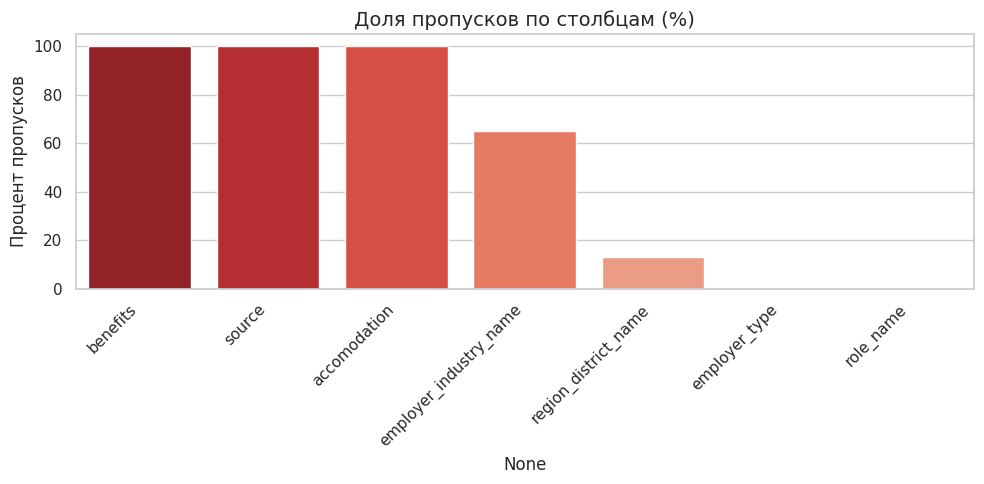

In [ ]:
# Визуализация пропусков в виде столбчатой диаграммы
plt.figure(figsize=(10, 5))
sns.barplot(x=missing_df.index, y=missing_df['Процент (%)'], palette='Reds_r')
plt.title('Доля пропусков по столбцам (%)', fontsize=14)
plt.ylabel('Процент пропусков')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
cols_to_drop = missing_df[missing_df['Процент (%)'] > 90].index.tolist()
print(f"Удаляем столбцы (>90% пропусков): {cols_to_drop}")
df.drop(columns=cols_to_drop, inplace=True, errors='ignore')  # ← errors='ignore'

irrelevant = ['id', 'link', 'last_found_at', 'description', 'raw_skills',
              'employer_id', 'country_id', 'region_id', 'region_district_id',
              'employer_industry_id', 'role_id']
df.drop(columns=[c for c in irrelevant if c in df.columns], inplace=True)
print(f"\nОставшиеся столбцы ({len(df.columns)}): {df.columns.tolist()}")

Удаляем столбцы (>90% пропусков): ['benefits', 'source', 'accomodation']

Оставшиеся столбцы (20): ['data_source', 'is_open', 'name', 'salary_from', 'salary_to', 'salary', 'experience', 'employer_name', 'employer_type', 'employer_industry_name', 'has_test', 'languages', 'accept_kids', 'accept_handicapped', 'schedule', 'employment', 'country_name', 'region_name', 'region_district_name', 'role_name']


In [ ]:

for col in df.columns:
    if df[col].isnull().sum() > 0:
        if df[col].dtype == 'object':
            df[col].fillna('Unknown', inplace=True)
            print(f"  '{col}' → заполнено 'Unknown'")
        else:
            median_val = df[col].median()
            df[col].fillna(median_val, inplace=True)
            print(f"  '{col}' → заполнено медианой ({median_val})")

print(f"\nПропусков после заполнения: {df.isnull().sum().sum()}")

  'employer_type' → заполнено 'Unknown'
  'employer_industry_name' → заполнено 'Unknown'
  'region_district_name' → заполнено 'Unknown'
  'role_name' → заполнено 'Unknown'

Пропусков после заполнения: 0


## 3. Анализ целевой переменной и обработка выбросов



In [ ]:
# Фильтруем вакансии с указанной зарплатой
df = df[df['salary'] > 0].copy()
print(f"Строк с указанной зарплатой: {len(df)}")
print(df['salary'].describe())

Строк с указанной зарплатой: 914
count    9.140000e+02
mean     2.928436e+05
std      2.424110e+06
min      1.500000e+02
25%      7.000000e+04
50%      1.000000e+05
75%      2.000000e+05
max      6.000000e+07
Name: salary, dtype: float64


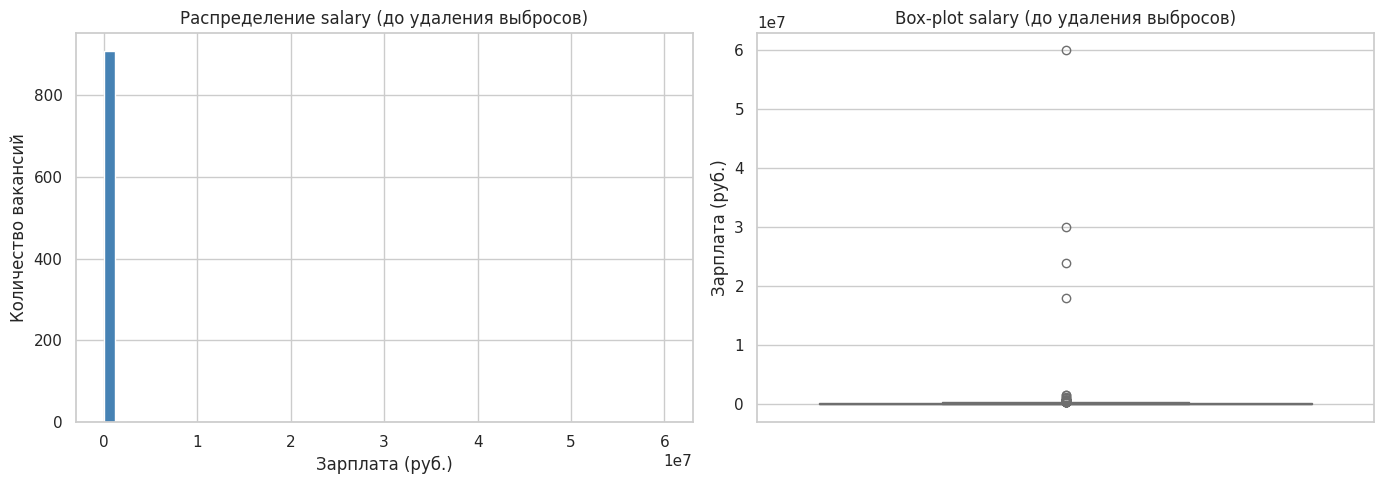

In [ ]:
# Визуализация распределения зарплат (исходное)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df['salary'], bins=50, color='steelblue', edgecolor='white')
axes[0].set_title('Распределение salary (до удаления выбросов)')
axes[0].set_xlabel('Зарплата (руб.)')
axes[0].set_ylabel('Количество вакансий')

sns.boxplot(y=df['salary'], ax=axes[1], color='lightcoral')
axes[1].set_title('Box-plot salary (до удаления выбросов)')
axes[1].set_ylabel('Зарплата (руб.)')

plt.tight_layout()
plt.show()

In [ ]:
# Удаление выбросов методом IQR
Q1 = df['salary'].quantile(0.25)
Q3 = df['salary'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"Q1 = {Q1:,.0f}")
print(f"Q3 = {Q3:,.0f}")
print(f"IQR = {IQR:,.0f}")
print(f"Нижняя граница: {lower_bound:,.0f}")
print(f"Верхняя граница: {upper_bound:,.0f}")

outliers_count = len(df[(df['salary'] < lower_bound) | (df['salary'] > upper_bound)])
print(f"\nВыбросов обнаружено: {outliers_count} ({outliers_count/len(df)*100:.1f}%)")

Q1 = 70,000
Q3 = 200,000
IQR = 130,000
Нижняя граница: -125,000
Верхняя граница: 395,000

Выбросов обнаружено: 63 (6.9%)


Строк до очистки: 914
Строк после удаления выбросов: 851


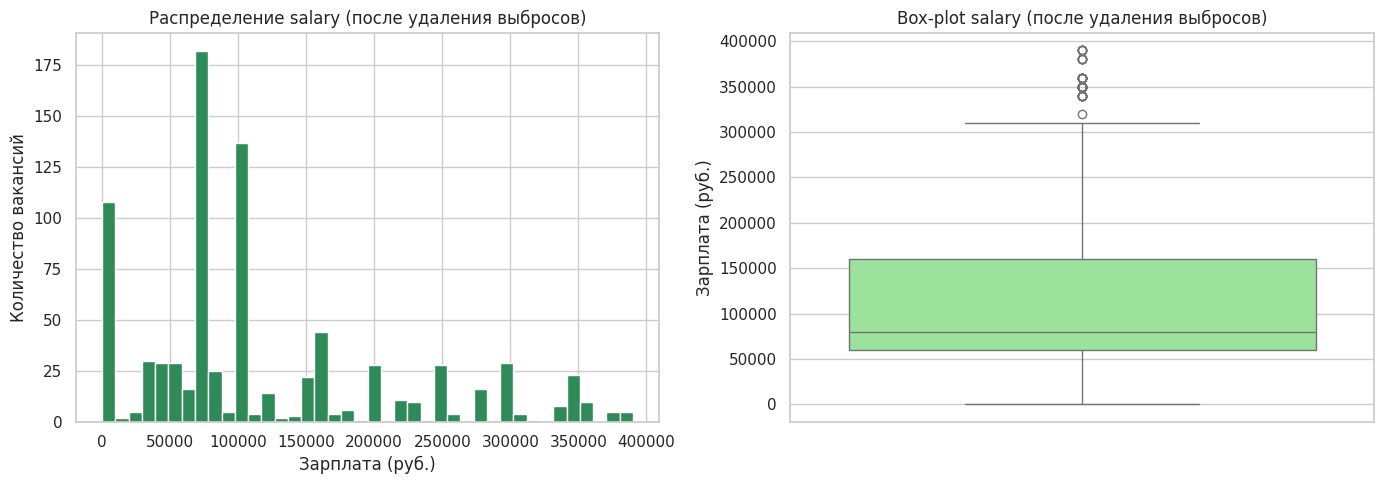

In [ ]:
# Удаляем выбросы
df_clean = df[(df['salary'] >= lower_bound) & (df['salary'] <= upper_bound)].copy()
print(f"Строк до очистки: {len(df)}")
print(f"Строк после удаления выбросов: {len(df_clean)}")

# Визуализация после очистки
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df_clean['salary'], bins=40, color='seagreen', edgecolor='white')
axes[0].set_title('Распределение salary (после удаления выбросов)')
axes[0].set_xlabel('Зарплата (руб.)')
axes[0].set_ylabel('Количество вакансий')

sns.boxplot(y=df_clean['salary'], ax=axes[1], color='lightgreen')
axes[1].set_title('Box-plot salary (после удаления выбросов)')
axes[1].set_ylabel('Зарплата (руб.)')

plt.tight_layout()
plt.show()

## 4. Разведочный анализ данных (EDA)




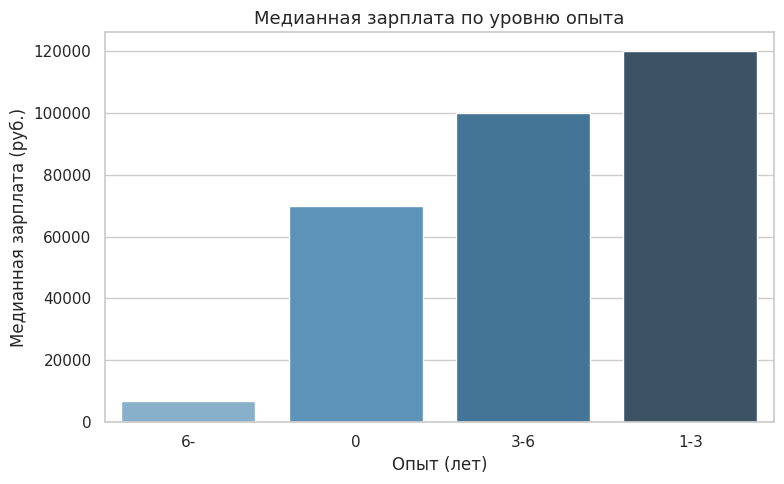

In [ ]:
# Средняя зарплата по опыту работы
plt.figure(figsize=(8, 5))
exp_salary = df_clean.groupby('experience')['salary'].median().sort_values()
sns.barplot(x=exp_salary.index, y=exp_salary.values, palette='Blues_d')
plt.title('Медианная зарплата по уровню опыта', fontsize=13)
plt.xlabel('Опыт (лет)')
plt.ylabel('Медианная зарплата (руб.)')
plt.tight_layout()
plt.show()

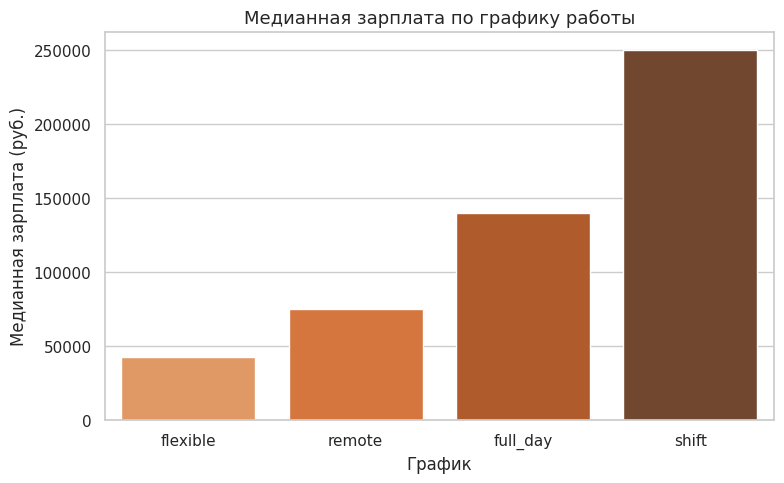

In [ ]:
# Средняя зарплата по формату работы (schedule)
plt.figure(figsize=(8, 5))
sched_salary = df_clean.groupby('schedule')['salary'].median().sort_values()
sns.barplot(x=sched_salary.index, y=sched_salary.values, palette='Oranges_d')
plt.title('Медианная зарплата по графику работы', fontsize=13)
plt.xlabel('График')
plt.ylabel('Медианная зарплата (руб.)')
plt.tight_layout()
plt.show()

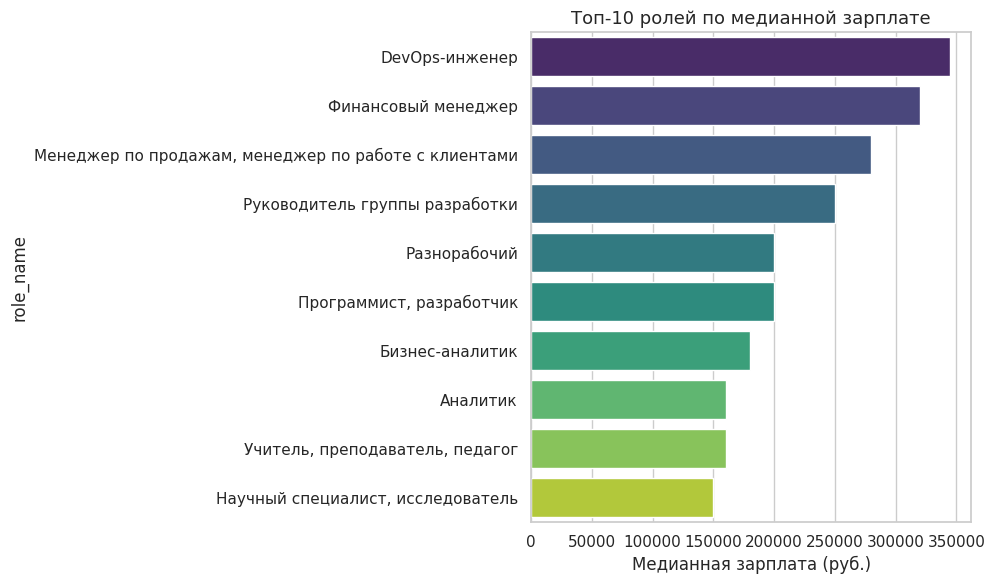

In [ ]:
# Топ-10 ролей по средней зарплате
top_roles = df_clean.groupby('role_name')['salary'].median().sort_values(ascending=False).head(10)
plt.figure(figsize=(10, 6))
sns.barplot(x=top_roles.values, y=top_roles.index, palette='viridis')
plt.title('Топ-10 ролей по медианной зарплате', fontsize=13)
plt.xlabel('Медианная зарплата (руб.)')
plt.tight_layout()
plt.show()

## 5. Кодирование категориальных данных


In [ ]:
# Определяем категориальные признаки
cat_cols = df_clean.select_dtypes(include='object').columns.tolist()
print(f"Категориальные признаки ({len(cat_cols)}): {cat_cols}")
print()
for col in cat_cols:
    print(f"  {col}: {df_clean[col].nunique()} уникальных значений")

Категориальные признаки (13): ['data_source', 'name', 'experience', 'employer_name', 'employer_type', 'employer_industry_name', 'languages', 'schedule', 'employment', 'country_name', 'region_name', 'region_district_name', 'role_name']

  data_source: 3 уникальных значений
  name: 338 уникальных значений
  experience: 4 уникальных значений
  employer_name: 258 уникальных значений
  employer_type: 4 уникальных значений
  employer_industry_name: 9 уникальных значений
  languages: 6 уникальных значений
  schedule: 4 уникальных значений
  employment: 4 уникальных значений
  country_name: 8 уникальных значений
  region_name: 92 уникальных значений
  region_district_name: 9 уникальных значений
  role_name: 39 уникальных значений


In [ ]:
# Label Encoding для признаков с небольшим числом уникальных значений
label_enc_cols = ['experience', 'schedule', 'employment', 'employer_type', 'data_source']

le = LabelEncoder()
for col in label_enc_cols:
    df_clean[col] = le.fit_transform(df_clean[col].astype(str))
    print(f"Label Encoded: '{col}'")

Label Encoded: 'experience'
Label Encoded: 'schedule'
Label Encoded: 'employment'
Label Encoded: 'employer_type'
Label Encoded: 'data_source'


In [ ]:
# Frequency Encoding для признаков с большим числом уникальных значений
freq_enc_cols = ['role_name', 'employer_name', 'region_name', 'country_name',
                 'region_district_name', 'employer_industry_name']

for col in freq_enc_cols:
    if col in df_clean.columns:
        freq_map = df_clean[col].value_counts() / len(df_clean)
        df_clean[col] = df_clean[col].map(freq_map)
        print(f"Frequency Encoded: '{col}'")

Frequency Encoded: 'role_name'
Frequency Encoded: 'employer_name'
Frequency Encoded: 'region_name'
Frequency Encoded: 'country_name'
Frequency Encoded: 'region_district_name'
Frequency Encoded: 'employer_industry_name'


In [ ]:
# Проверяем — все ли признаки теперь числовые
print("Типы данных после кодирования:")
print(df_clean.dtypes)
print(f"\nОсталось нечисловых: {df_clean.select_dtypes(include='object').shape[1]}")

Типы данных после кодирования:
data_source                 int64
is_open                     int64
name                       object
salary_from                 int64
salary_to                   int64
salary                      int64
experience                  int64
employer_name             float64
employer_type               int64
employer_industry_name    float64
has_test                    int64
languages                  object
accept_kids                 int64
accept_handicapped          int64
schedule                    int64
employment                  int64
country_name              float64
region_name               float64
region_district_name      float64
role_name                 float64
dtype: object

Осталось нечисловых: 2


## 6. Преобразование числовых данных (масштабирование)



In [ ]:
# Определяем признаки и целевую переменную
target = 'salary'
feature_cols = [c for c in df_clean.columns if c != target]

X = df_clean[feature_cols].copy()
y = df_clean[target].copy()

print(f"Признаки: {X.shape[1]} столбцов, {X.shape[0]} строк")
print(f"Целевая переменная: {target}")
print()
print("Пример данных X:")
X.head()

Признаки: 19 столбцов, 851 строк
Целевая переменная: salary

Пример данных X:


,data_source,is_open,name,salary_from,salary_to,experience,employer_name,employer_type,employer_industry_name,has_test,languages,accept_kids,accept_handicapped,schedule,employment,country_name,region_name,region_district_name,role_name
0,0,0,Middle+/Senior Computer Vision Researcher (уда...,250000,350000,2,0.010576,2,0.833137,1,[],0,0,2,0,0.86839,0.244418,0.343126,0.254994
2,0,0,Java back-end разработчик в ML команду ранжиро...,220000,360000,1,0.021152,2,0.129260,0,[],0,0,2,0,0.86839,0.244418,0.343126,0.254994
3,0,0,Computer Vision Engineer (удаленно),200000,250000,1,0.010576,2,0.833137,1,[],0,0,2,0,0.86839,0.076381,0.122209,0.086957
6,0,0,Junior+/Middle MLOps-Engineer,110000,0,1,0.003525,2,0.833137,0,[],0,0,1,0,0.86839,0.244418,0.343126,0.254994
16,0,0,Аналитик данных (Data Science),50000,100000,1,0.001175,2,0.833137,0,[],0,0,2,0,0.86839,0.032902,0.151586,0.086957


In [ ]:
# Применяем StandardScaler к числовым признакам
# (кроме уже закодированных бинарных флагов is_open, has_test и т.д.)
scale_cols = ['salary_from', 'salary_to']
scale_cols = [c for c in scale_cols if c in X.columns]

scaler = StandardScaler()
X_scaled = X.copy()
X_scaled[scale_cols] = scaler.fit_transform(X[scale_cols])

print(f"Масштабированные признаки: {scale_cols}")
print()
print("Статистика после масштабирования:")
X_scaled[scale_cols].describe().round(3)

Масштабированные признаки: ['salary_from', 'salary_to']

Статистика после масштабирования:


,salary_from,salary_to
count,851.000,851.000
mean,0.000,0.000
std,1.001,1.001
min,-0.938,-0.737
25%,-0.938,-0.737
50%,-0.183,-0.663
75%,0.571,0.195
max,3.464,2.899


## 7. Разделение на обучающую и тестовую выборки


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y,
    test_size=0.2,
    random_state=42
)

print(f"Всего примеров: {len(X_scaled)}")
print(f"Обучающая выборка (X_train): {X_train.shape}")
print(f"Тестовая выборка  (X_test):  {X_test.shape}")
print()
print(f"Доля обучающих: {len(X_train)/len(X_scaled)*100:.1f}%")
print(f"Доля тестовых:  {len(X_test)/len(X_scaled)*100:.1f}%")

Всего примеров: 851
Обучающая выборка (X_train): (680, 19)
Тестовая выборка  (X_test):  (171, 19)

Доля обучающих: 79.9%
Доля тестовых:  20.1%


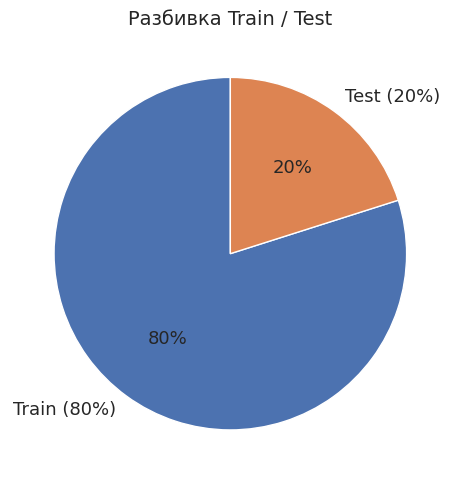

In [ ]:
# Визуализация разбивки
labels = ['Train (80%)', 'Test (20%)']
sizes  = [len(X_train), len(X_test)]
colors = ['#4C72B0', '#DD8452']

plt.figure(figsize=(5, 5))
plt.pie(sizes, labels=labels, colors=colors, autopct='%1.0f%%',
        startangle=90, textprops={'fontsize': 13})
plt.title('Разбивка Train / Test', fontsize=14)
plt.tight_layout()
plt.show()

## 8. Обучение модели — Random Forest Regressor


In [ ]:
# Финальная подготовка перед обучением

# 1. Удаляем все оставшиеся строковые столбцы
str_cols = X_train.select_dtypes(include='object').columns.tolist()
if str_cols:
    print(f"Удаляем строковые столбцы: {str_cols}")
    X_train = X_train.drop(columns=str_cols)
    X_test  = X_test.drop(columns=str_cols)

# 2. Заполняем NaN нулями (на случай если остались после map())
X_train = X_train.fillna(0)
X_test  = X_test.fillna(0)

# 3. Принудительно приводим всё к float
X_train = X_train.astype(float)
X_test  = X_test.astype(float)

print(f"X_train shape: {X_train.shape}")
print(f"Типов object осталось: {X_train.select_dtypes(include='object').shape[1]}")


# Создаём и обучаем модель Random Forest
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)



Удаляем строковые столбцы: ['name', 'languages']
X_train shape: (680, 17)
Типов object осталось: 0


RandomForestRegressor(max_depth=10, min_samples_leaf=5, n_jobs=-1,
                      random_state=42)

## 9. Оценка качества модели



In [ ]:
# Предсказания на тестовой выборке
y_pred = rf_model.predict(X_test)

# Метрики
mae  = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2   = r2_score(y_test, y_pred)

print("=" * 45)
print("       РЕЗУЛЬТАТЫ МОДЕЛИ (тест)")
print("=" * 45)
print(f"  MAE  (средняя ошибка):    {mae:>12,.0f} руб.")
print(f"  RMSE (средн. кв. ошибка): {rmse:>12,.0f} руб.")
print(f"  R²   (объяснённая дисп.): {r2:>12.4f}")
print("=" * 45)

       РЕЗУЛЬТАТЫ МОДЕЛИ (тест)
  MAE  (средняя ошибка):           2,686 руб.
  RMSE (средн. кв. ошибка):        6,230 руб.
  R²   (объяснённая дисп.):       0.9958


In [ ]:
# Также проверим на обучающей выборке (для диагностики переобучения)
y_train_pred = rf_model.predict(X_train)
r2_train = r2_score(y_train, y_train_pred)
r2_test  = r2_score(y_test, y_pred)

print(f"R² на обучающей выборке: {r2_train:.4f}")
print(f"R² на тестовой выборке:  {r2_test:.4f}")
if r2_train - r2_test > 0.15:
    print("⚠️  Возможно переобучение — разница R² > 0.15")
else:
    print("✅  Модель хорошо обобщается (нет явного переобучения)")

R² на обучающей выборке: 0.9986
R² на тестовой выборке:  0.9958
✅  Модель хорошо обобщается (нет явного переобучения)


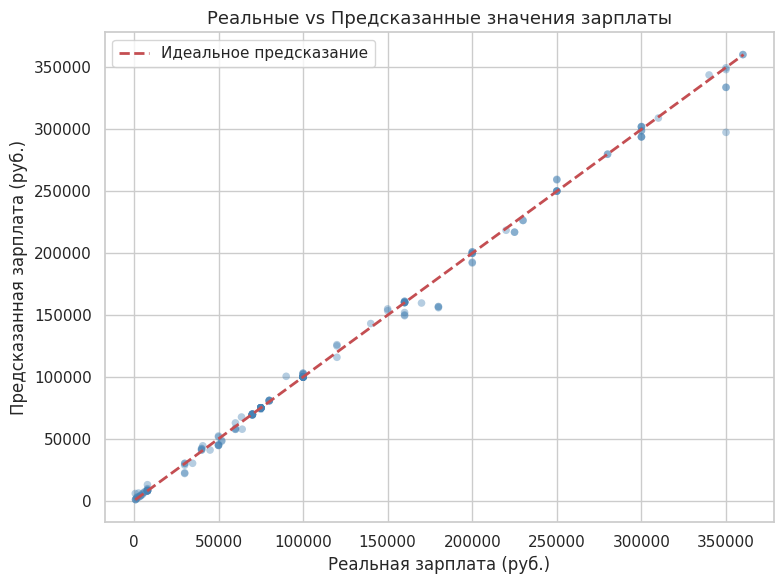

In [ ]:
# Визуализация: реальные vs предсказанные значения
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.4, color='steelblue', edgecolors='none', s=30)
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Идеальное предсказание')
plt.xlabel('Реальная зарплата (руб.)', fontsize=12)
plt.ylabel('Предсказанная зарплата (руб.)', fontsize=12)
plt.title('Реальные vs Предсказанные значения зарплаты', fontsize=13)
plt.legend()
plt.tight_layout()
plt.show()

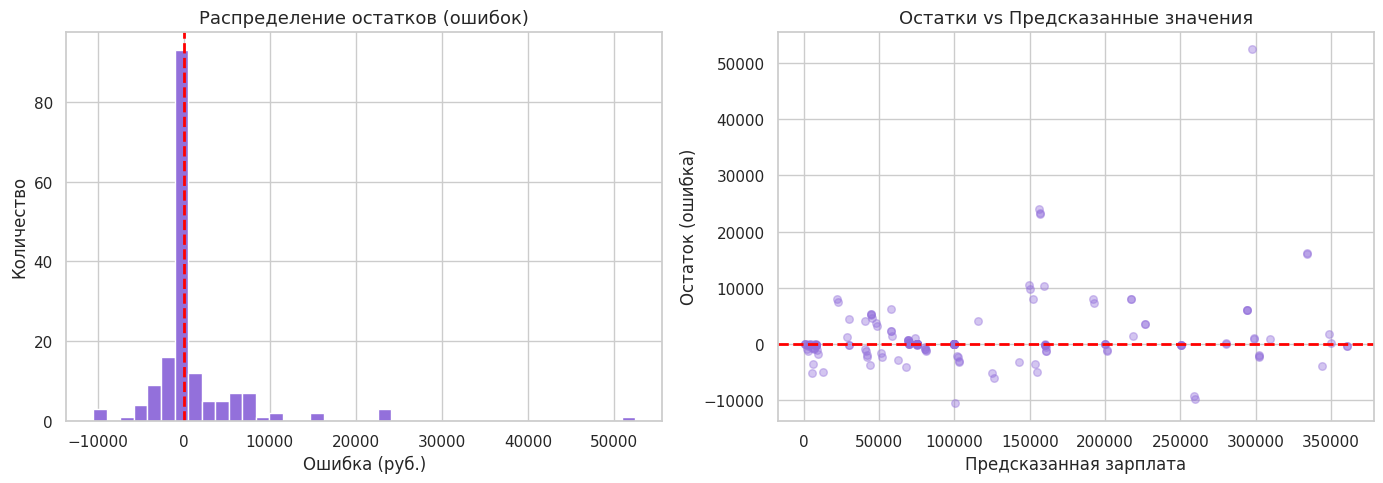

In [ ]:
# Распределение остатков (residuals)
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(residuals, bins=40, color='mediumpurple', edgecolor='white')
axes[0].axvline(0, color='red', linestyle='--', lw=2)
axes[0].set_title('Распределение остатков (ошибок)', fontsize=13)
axes[0].set_xlabel('Ошибка (руб.)')
axes[0].set_ylabel('Количество')

axes[1].scatter(y_pred, residuals, alpha=0.4, color='mediumpurple', s=30)
axes[1].axhline(0, color='red', linestyle='--', lw=2)
axes[1].set_title('Остатки vs Предсказанные значения', fontsize=13)
axes[1].set_xlabel('Предсказанная зарплата')
axes[1].set_ylabel('Остаток (ошибка)')

plt.tight_layout()
plt.show()

## 10. Важность признаков (Feature Importance)



In [ ]:
# Извлекаем важность признаков
importances = rf_model.feature_importances_
feat_names  = X_train.columns.tolist()

feat_imp_df = pd.DataFrame({
    'Признак': feat_names,
    'Важность': importances
}).sort_values('Важность', ascending=False).head(15)

print("Топ-15 важных признаков:")
print(feat_imp_df.to_string(index=False))

Топ-15 важных признаков:
               Признак     Важность
             salary_to 6.355852e-01
           salary_from 3.584599e-01
          country_name 5.013874e-03
         employer_name 3.610264e-04
            experience 2.879173e-04
             role_name 8.341864e-05
              schedule 6.376618e-05
           region_name 5.907312e-05
  region_district_name 5.367807e-05
employer_industry_name 1.909314e-05
            employment 6.566256e-06
         employer_type 4.115043e-06
              has_test 1.089331e-06
               is_open 7.751165e-07
    accept_handicapped 4.461068e-07


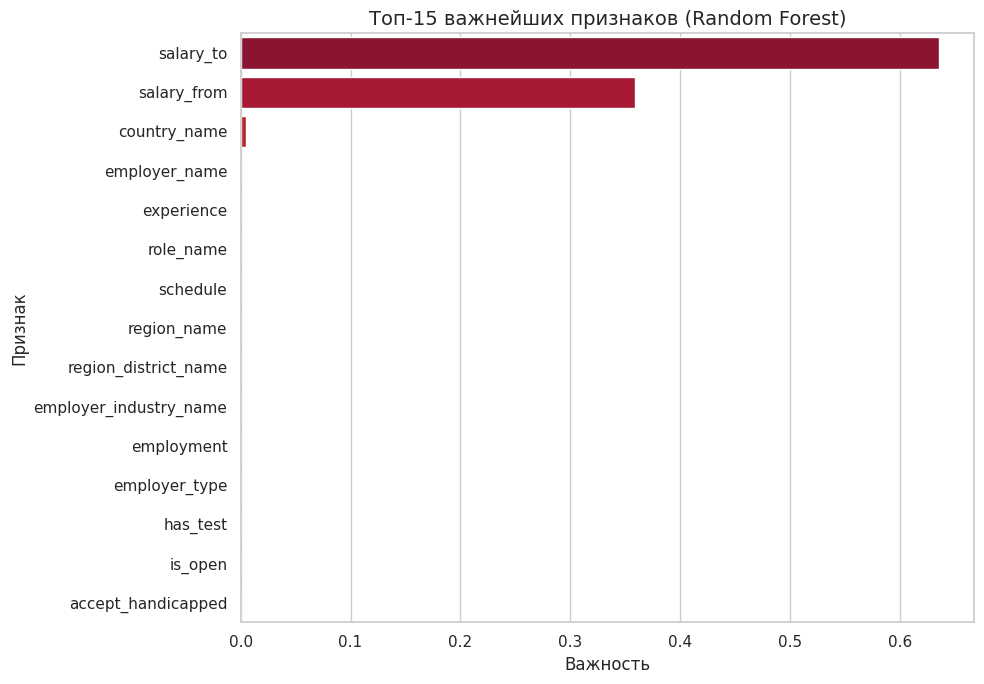

In [ ]:
# Визуализация важности признаков
plt.figure(figsize=(10, 7))
sns.barplot(
    data=feat_imp_df,
    x='Важность',
    y='Признак',
    palette='YlOrRd_r'
)
plt.title('Топ-15 важнейших признаков (Random Forest)', fontsize=14)
plt.xlabel('Важность')
plt.ylabel('Признак')
plt.tight_layout()
plt.show()